In [15]:
import scienceplots
import matplotlib.pyplot as plt
plt.style.use(["science", "no-latex", "grid"])

import warnings
warnings.filterwarnings("ignore")

import scipy
from torchdiffeq import odeint

# Itotal and Hi visualisation
We performed experiments using 10 different random initializations. For each run, we calculated the mean squared error (MSE) loss between the predicted output and the ground truth. The result with the minimum loss was selected, along with its associated neural parameter calibration (NPC), Disease-Informed Neural Network (DINN) and Neural Emulation-Calibration (NEC) cumulative dengue cases prediction. These NPC predictions can then be compared with cumulative dengue cases predicted by Markov Chain Monte Carlo (MCMC) sampling.

In [16]:
import os
import torch
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def select_best_Hitotal(data, Hitotal_true):
    """
    For each set of Hitotal in data, compute the MSE loss with Hitotal_true,
    and return the Hitotal set with the lowest loss.
    """
    Hitotal_true_tensor = torch.tensor(Hitotal_true, dtype=torch.float32).log1p()
    min_loss = float('inf')
    best_Hitotal = None
    mse_loss = torch.nn.MSELoss()
    for i in range(data.shape[0]):
        Hitotal_tensor = torch.tensor(data[i], dtype=torch.float32).log1p()
        loss = mse_loss(Hitotal_tensor, Hitotal_true_tensor)
        if loss < min_loss:
            min_loss = loss
            best_Hitotal = data[i]
    print(f"MSE loss of NPC: {min_loss.item()}")
    return best_Hitotal

def average_Hitotal(data):
    """
    Compute the elementwise average of all Hitotal sets in data (in log1p space)
    and return it.
    """
    data_tensor = torch.tensor(data, dtype=torch.float32)
    avg_Hitotal = data_tensor.mean(dim=0)
    return avg_Hitotal.numpy()

def npc_Hitotal_pred(base_dir, Hitotal_true):
    """
        Compute the median and standard deviation of NPC Hitotal predictions across all unis in the given base directory.
    """
    uni_dirs = sorted(glob.glob(os.path.join(base_dir, "uni*/data_pred_obser.csv")))

    # Load all nn_prediction columns into a list of Series
    npc_predictions = []
    for csv_path in uni_dirs:
        df = pd.read_csv(csv_path)
        if "nn_prediction" in df.columns:
            npc_predictions.append(df["nn_prediction"].reset_index(drop=True))

    # Align all series to the shortest length
    min_len = min(len(s) for s in npc_predictions)
    npc_predictions = [s.iloc[:min_len] for s in npc_predictions]
    data = np.stack([s.values for s in npc_predictions])

    # Compute median and std for Hitotal across unis for each time point
    Hitotal_npc = average_Hitotal(data)
    Hitotal_npc_std = np.std(data, axis=0)

    # Compute Hi (weekly cases) and its std across unis
    hi_npc_all = np.diff(data, axis=1, prepend=data[:, [0]])  # shape: (n_unis, n_time)
    Hitotal_npc_diff = np.insert(Hitotal_npc, 0, Hitotal_true[0])
    hi_npc = np.diff(Hitotal_npc_diff)  # shape: (n_time,)
    hi_npc_std = np.std(hi_npc_all, axis=0)

    return (
        pd.Series(Hitotal_npc),
        pd.Series(Hitotal_npc_std),
        pd.Series(hi_npc),
        pd.Series(hi_npc_std)
    )

def run_dengue_ode(parameters, Hitotal0, t_true):
    """
    Run the dengue ODE system for a given parameter set and initial Hitotal value.
    Returns the predicted Hitotal time series.
    """
    def apollo_model_7(t, y, params):
        """ODE system for the Dengue model
        Args:
            t: Time point
            y: State vector [Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi]
            parameters: Dictionary containing model parameters
        """
        Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi = y
        lambda_, beta_m, mu_m, theta_m, mu_h, beta_h, theta_h, gamma_h = params

        # Calculate total populations
        H = Hr + Hs + He + Hi  # Total human population
        M = Me + Ms + Mi  # Total mosquito population

        # Ensure populations are not zero
        H = torch.clamp(H, min=1e-8)
        M = torch.clamp(M, min=1e-8)

        # ODE system
        dydt = torch.stack(
            [
                theta_h * He,
                theta_h * He - (gamma_h + mu_h) * Hi,
                beta_m * Hi * Ms / H - (theta_m + mu_m) * Me,
                gamma_h * Hi - mu_h * Hr,
                mu_h * H - beta_h * Mi * Hs / M - mu_h * Hs,
                beta_h * Mi * Hs / M - (theta_h + mu_h) * He,
                lambda_ - beta_m * Hi * Ms / H - mu_m * Ms,
                theta_m * Me - mu_m * Mi,
            ]
        )
        return dydt

    # Initial state
    Hitotal0 = Hitotal0.squeeze(1)
    y0 = torch.stack(
        [
            Hitotal0,
            parameters["Hi0"],
            parameters["Me0"],
            parameters["Hr0"],
            parameters["Hs0"],
            parameters["He0"],
            parameters["Ms0"],
            parameters["Mi0"],
        ]
    )
    params = torch.stack(
        [
            parameters["lambda"],
            parameters["beta_m"],
            parameters["mu_m"],
            parameters["theta_m"],
            parameters["mu_h"],
            parameters["beta_h"],
            parameters["theta_h"],
            parameters["gamma_h"],
        ]
    )
    
    # Solve ODE system
    solution = odeint(
        func=lambda y, t: apollo_model_7(y, t, params),
        y0=y0,
        t=t_true,
        method="dopri5",  # dopri5, euler, or rk4
        rtol=1e-3,  # Relaxed tolerance
        atol=1e-6,  # Relaxed absolute tolerance
    )
    
    # Post-process solution
    mcmc_Hitotal_pred = torch.abs(solution[1:, 0].squeeze())  # Hitotal variable
    mcmc_Hitotal_pred = torch.expm1(mcmc_Hitotal_pred)
    return mcmc_Hitotal_pred

def mcmc_predict(mat_path, mat_name, Hitotal_true, t_points, param_names=None):
    """
    Load MCMC parameters from .mat file, run ODE for each, compute loss to ground truth,
    and select the prediction with the smallest loss but closest to NPC prediction.
    Returns: best_pred_Hitotal, best_loss, best_params
    """
    if param_names is None:
        param_names = ['Hi0', 'Me0', 'Hr0', 'Hs0', 'He0', 'Ms0', 'Mi0',
                       'beta_h', 'beta_m', 'gamma_h', 'lambda', 'mu_m', 'theta_h', 'theta_m']
    
    mat = scipy.io.loadmat(mat_path)
    raw = mat[mat_name]
    params_mcmc = raw.T      # shape: (n_sets, n_parameters)
    n_sets, n_params = params_mcmc.shape

    # Helper: build params dict from a 1D vector of length n_params
    def build_params(row_vec):
        p = np.asarray(row_vec).ravel()
        params = {name: torch.tensor([p[j]], dtype=torch.float64) for j, name in enumerate(param_names)}
        params["mu_h"] = torch.tensor([0.0004], dtype=torch.float64)  # constant
        return params

    # MCMC estimation from the best (first) set
    best_set = params_mcmc[0, :]
    params = build_params(best_set)
    Hitotal0 = torch.log1p(torch.as_tensor(Hitotal_true[0], dtype=torch.float64)).reshape(1, 1)
    mcmc_Hitotal = run_dengue_ode(params, Hitotal0, t_points)
    mcmc_hi  = np.diff(mcmc_Hitotal, prepend=mcmc_Hitotal[0])
    
    # Std of all MCMC set
    mcmc_Hitotal_all = []
    mcmc_hi_all = []
    for i in range(n_sets):
        prms = build_params(params_mcmc[i, :])
        mcmc_Hitotal_i = run_dengue_ode(prms, Hitotal0, t_points)
        mcmc_Hitotal_all.append(np.asarray(mcmc_Hitotal_i).ravel())

        mcmc_hi_i  = np.diff(mcmc_Hitotal_i, prepend=mcmc_Hitotal_i[0])
        mcmc_hi_all.append(np.asarray(mcmc_hi_i).ravel())

    mcmc_Hitotal_all = np.vstack(mcmc_Hitotal_all)             # (window, T)
    mcmc_Hitotal_std = np.std(mcmc_Hitotal_all, axis=0)

    mcmc_hi_all = np.vstack(mcmc_hi_all)               # (window, T)
    mcmc_hi_std = np.std(mcmc_hi_all, axis=0)

    return mcmc_Hitotal, mcmc_Hitotal_std, mcmc_hi, mcmc_hi_std

### Bello

In [17]:
# Ground truth
bello_hi_true = pd.read_csv(
    'bello/DataBello_full.csv')[737:785]['Cases'].reset_index(drop=True)
bello_Hitotal_true = bello_hi_true.cumsum()

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
bello_Hitotal_mcmc, bello_Hitotal_mcmc_std, bello_hi_mcmc, bello_hi_mcmc_std = mcmc_predict(
    "bello/bello_MCMC_all_params.mat", "bello_mcmc", 
    bello_Hitotal_true, t_points)

# NPC predictions
bello_Hitotal_npc, bello_Hitotal_npc_std, bello_hi_npc, bello_hi_npc_std = npc_Hitotal_pred("./bello/data", bello_Hitotal_true)

### Iquitos

In [18]:
# Ground truth
iquitos_hi_true = pd.read_csv(
    'iquitos/DataIquitos_full.csv')[265:313]['Cases'].reset_index(drop=True)
iquitos_Hitotal_true = iquitos_hi_true.cumsum()

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
iquitos_Hitotal_mcmc, iquitos_Hitotal_mcmc_std, iquitos_hi_mcmc, iquitos_hi_mcmc_std = mcmc_predict(
    "iquitos/iquitos_MCMC_all_params.mat", "iquitos_mcmc", 
    iquitos_Hitotal_true, t_points)

# NPC predictions
iquitos_Hitotal_npc, iquitos_Hitotal_npc_std, iquitos_hi_npc, iquitos_hi_npc_std = npc_Hitotal_pred("./iquitos/data", iquitos_Hitotal_true)

### SanJuan

In [19]:
# Ground truth
sanjuan_hi_true = pd.read_csv(
    'sanjuan/DataSanJuan_full.csv')[570:618]['Cases'].reset_index(drop=True)
sanjuan_Hitotal_true = sanjuan_hi_true.cumsum()

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
sanjuan_Hitotal_mcmc, sanjuan_Hitotal_mcmc_std, sanjuan_hi_mcmc, sanjuan_hi_mcmc_std = mcmc_predict(
    "sanjuan/sanjuan_MCMC_all_params.mat", "sanjuan_mcmc", 
    sanjuan_Hitotal_true, t_points)

# NPC predictions
sanjuan_Hitotal_npc, sanjuan_Hitotal_npc_std, sanjuan_hi_npc, sanjuan_hi_npc_std = npc_Hitotal_pred("./sanjuan/data", sanjuan_Hitotal_true)

### Vietnam

In [20]:
# Ground truth
vietnam = pd.read_csv(
    "vietnam/data_vietnam_Hitotal_true_mcmc_cali.csv", index_col=0).reset_index(drop=True)
vietnam_Hitotal_true = vietnam["CumulativeHumanInfected_true"].reset_index(drop=True)
vietnam_hi_true = vietnam_Hitotal_true.diff().fillna(vietnam_Hitotal_true.iloc[0])

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
vietnam_Hitotal_mcmc, vietnam_Hitotal_mcmc_std, vietnam_hi_mcmc, vietnam_hi_mcmc_std = mcmc_predict(
    "vietnam/vietnam_MCMC_all_params.mat", "vietnam_mcmc", 
    vietnam_Hitotal_true, t_points)

# NPC predictions
vietnam_Hitotal_npc, vietnam_Hitotal_npc_std, vietnam_hi_npc, vietnam_hi_npc_std = npc_Hitotal_pred("./vietnam/data", vietnam_Hitotal_true)

### Philippines

In [21]:
# Ground truth
philippines = pd.read_csv(
    "philippines/data_philippines_Hitotal_true_mcmc_cali.csv", index_col=0).reset_index(drop=True)
philippines_Hitotal_true = philippines["CumulativeHumanInfected_true"].reset_index(drop=True)
philippines_hi_true = philippines_Hitotal_true.diff().fillna(philippines_Hitotal_true.iloc[0])

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
philippines_Hitotal_mcmc, philippines_Hitotal_mcmc_std, philippines_hi_mcmc, philippines_hi_mcmc_std = mcmc_predict(
    "philippines/philippines_MCMC_all_params.mat", "philippines_mcmc", 
    philippines_Hitotal_true, t_points)

# NPC predictions
philippines_Hitotal_npc, philippines_Hitotal_npc_std, philippines_hi_npc, philippines_hi_npc_std = npc_Hitotal_pred("./philippines/data", philippines_Hitotal_true)

### Cambodia

In [22]:
# Ground truth
cambodia = pd.read_csv(
    "cambodia/data_cambodia_Hitotal_true_mcmc_cali.csv", index_col=0).reset_index(drop=True)
cambodia_Hitotal_true = cambodia["CumulativeHumanInfected_true"].reset_index(drop=True)
cambodia_hi_true = cambodia_Hitotal_true.diff().fillna(cambodia_Hitotal_true.iloc[0])

# MCMC predictions
t_points = torch.arange(0, 49, dtype=torch.float32)
cambodia_Hitotal_mcmc, cambodia_Hitotal_mcmc_std, cambodia_hi_mcmc, cambodia_hi_mcmc_std = mcmc_predict(
    "cambodia/cambodia_MCMC_all_params.mat", "cambodia_mcmc", 
    cambodia_Hitotal_true, t_points)

# NPC predictions
cambodia_Hitotal_npc, cambodia_Hitotal_npc_std, cambodia_hi_npc, cambodia_hi_npc_std = npc_Hitotal_pred("./cambodia/data", cambodia_Hitotal_true)

### Visualize weekly infectious cases for all cities and countries

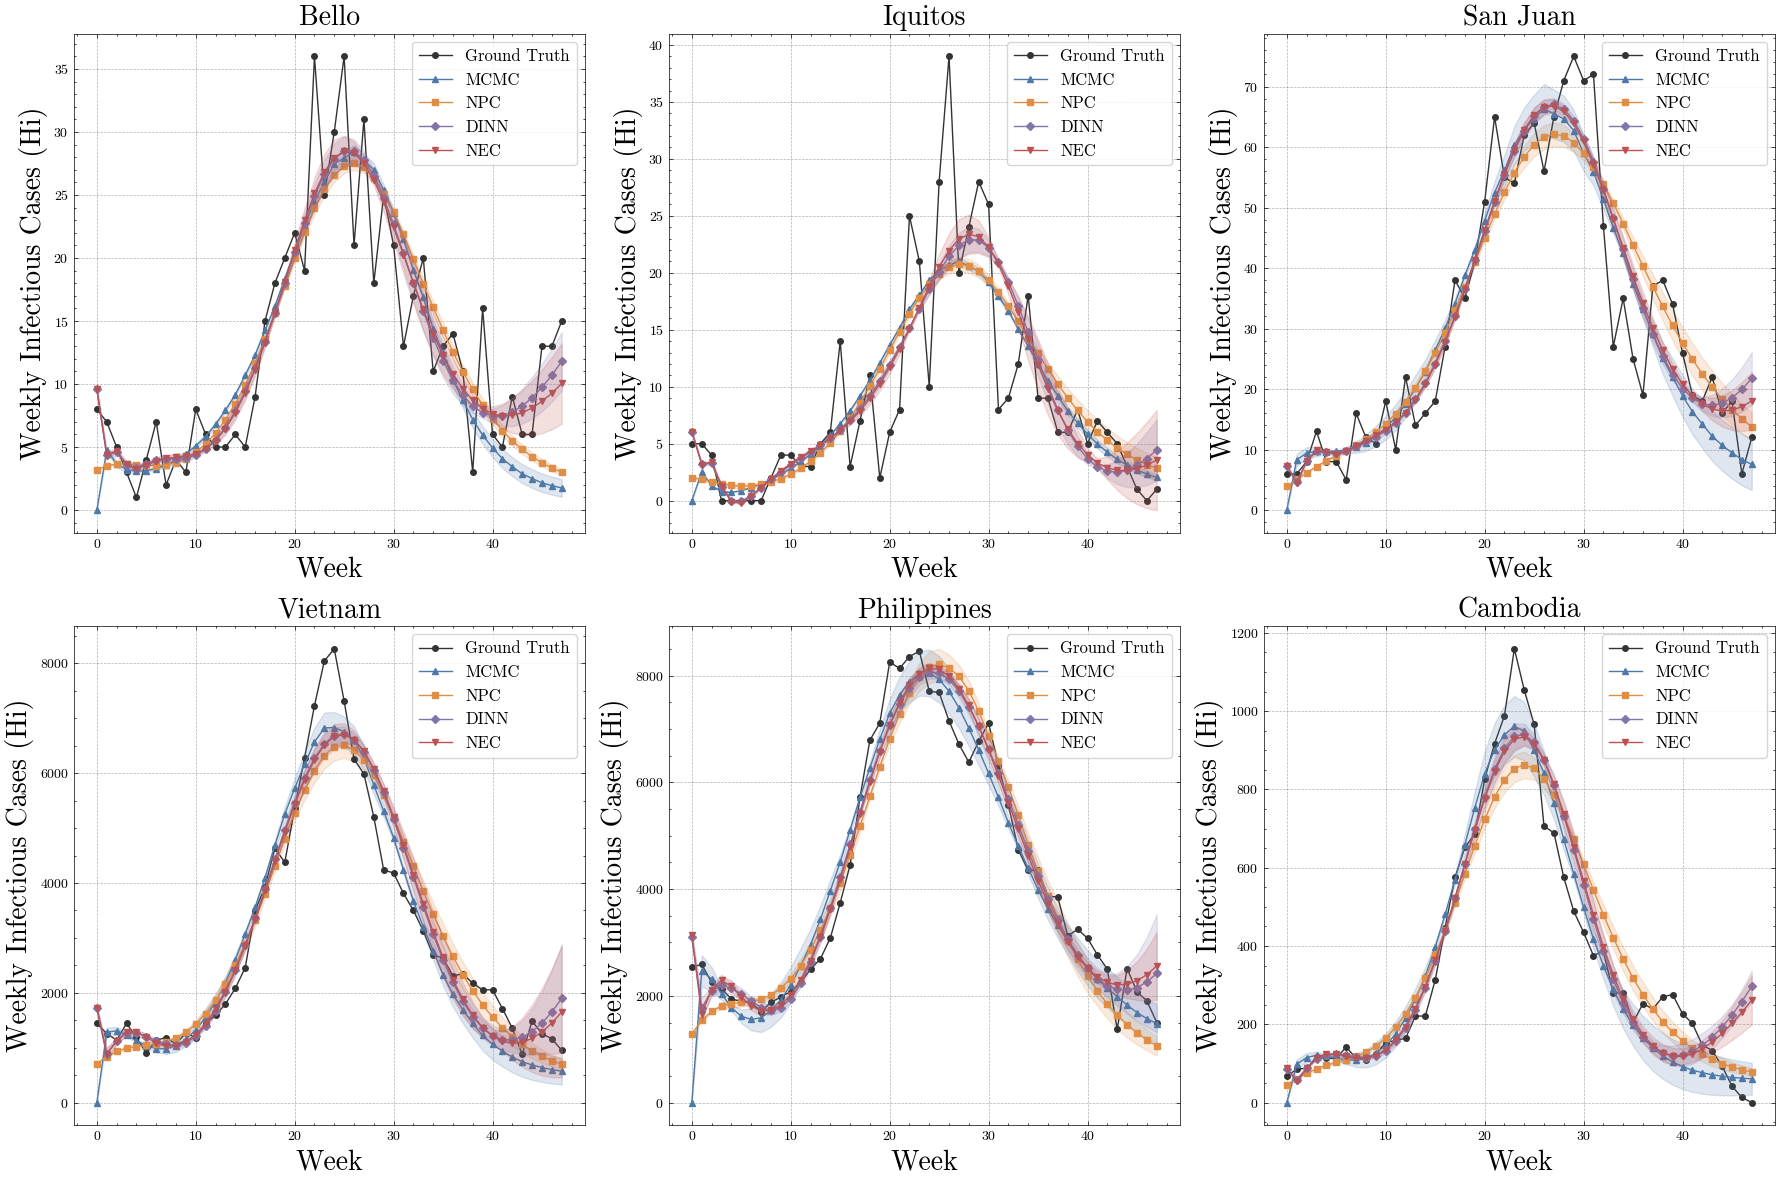

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob

# Create a 2x3 subplot layout (2 rows, 3 columns): cities on top, countries on bottom
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

regions = ['bello', 'iquitos', 'sanjuan', 'vietnam', 'philippines', 'cambodia']
titles = {'sanjuan': 'San Juan'}

# outputs/dinns_nec_predictions/<region_key>/ uses the short region keys from
# baseline_experiments.NPC_REGION_DIR
DINNS_NEC_PRED_DIR = "../outputs/dinns_nec_predictions"
REGION_KEY = {
    'bello': 'bello', 'iquitos': 'iquitos', 'sanjuan': 'sanjuan',
    'vietnam': 'vn', 'philippines': 'phi', 'cambodia': 'cam',
}


def dinns_nec_hi(region, model):
    """Mean/std weekly infectious cases (Hi) for `model` ('dinn' or 'nec') on the
    calibration split, averaged across all per-seed runs for `region`. Hi is the
    first difference of the predicted cumulative cases (Itot), matching how the
    ground-truth/NPC/MCMC Hi series above are derived from Hitotal."""
    region_key = REGION_KEY[region]
    seed_files = sorted(glob.glob(f"{DINNS_NEC_PRED_DIR}/{region_key}/seed*/{model}.csv"))
    hi_runs = []
    for path in seed_files:
        df = pd.read_csv(path)
        cal = df[(df["split"] == "calibration") & (df["target"] == "Itot")].sort_values("t")
        itot_pred = cal["predicted"].reset_index(drop=True)
        hi_runs.append(itot_pred.diff().fillna(itot_pred.iloc[0]).to_numpy())
    hi_runs = np.stack(hi_runs, axis=0)
    return hi_runs.mean(axis=0), hi_runs.std(axis=0)


for ax, region in zip(axes.ravel(), regions):
    ax.plot(eval(f"{region}_hi_true"), label="Ground Truth", marker='o', color='#333333', markersize=4)

    # MCMC
    ax.plot(eval(f"{region}_hi_mcmc"), label="MCMC", marker='^', color='#4E79A7', markersize=4)
    ax.fill_between(
        np.arange(len(eval(f"{region}_hi_mcmc"))),
        eval(f"{region}_hi_mcmc") - eval(f"{region}_hi_mcmc_std"),
        eval(f"{region}_hi_mcmc") + eval(f"{region}_hi_mcmc_std"),
        color='#4E79A7', alpha=0.18, zorder=2
    )

    # NPC
    ax.plot(eval(f"{region}_hi_npc"), label="NPC", marker='s', color='#E08E45', markersize=4)
    ax.fill_between(
        np.arange(len(eval(f"{region}_hi_npc"))),
        eval(f"{region}_hi_npc") - eval(f"{region}_hi_npc_std"),
        eval(f"{region}_hi_npc") + eval(f"{region}_hi_npc_std"),
        color='#E08E45', alpha=0.18, zorder=1
    )

    # DINN
    dinn_hi, dinn_hi_std = dinns_nec_hi(region, "dinn")
    ax.plot(dinn_hi, label="DINN", marker='D', color='#8175AA', markersize=4)
    ax.fill_between(
        np.arange(len(dinn_hi)),
        dinn_hi - dinn_hi_std,
        dinn_hi + dinn_hi_std,
        color='#8175AA', alpha=0.18, zorder=3
    )

    # NEC
    nec_hi, nec_hi_std = dinns_nec_hi(region, "nec")
    ax.plot(nec_hi, label="NEC", marker='v', color='#C0504D', markersize=4)
    ax.fill_between(
        np.arange(len(nec_hi)),
        nec_hi - nec_hi_std,
        nec_hi + nec_hi_std,
        color='#C0504D', alpha=0.18, zorder=4
    )

    ax.set_title(titles.get(region, region.title()), fontsize=20)
    ax.set_xlabel("Week", fontsize=20)
    ax.set_ylabel("Weekly Infectious Cases (Hi)", fontsize=20)
    ax.legend(loc='best', fontsize=12, ncol=1, framealpha=0.8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
# # Save figure with 300 dpi to TIFF file
fig.savefig("hi_visualization.png", dpi=300, format='png')
plt.show()


# Compute MSE of MCMC, NPC, DINN and NEC
This section presents the computation of Hitotal using two approaches: NPC, DINN and NEC after training, and MCMC following sampling performed in Matlab. Subsequently, we calculate the Mean Squared Error (MSE) loss of Hitotal by comparing the ground truth with NPC and MCMC results, respectively, and visualize these outcomes for comparison.

In [51]:
import os
import glob
import torch
import scipy
import numpy as np
import pandas as pds
import ruamel.yaml as yaml
from dantro._import_tools import import_module_from_path
from torchdiffeq import odeint

# Sibling project providing the NPC NeuralNet implementation, model configs,
# and calibration/projection data used by load_model() below.
NEURALABM_ROOT = "/home/hoang/Documents/VGU_projects/DigitalTwin/code/NeuralABM_dengue"

In [52]:
# NEURAL PARAMETERS CALIBRATION
def load_checkpoint(net, filepath):
    """Load model checkpoint from file

    Args:
        net: Model instance to load weights into
        filepath (str): Path to checkpoint file
    """
    try:
        # Load checkpoint
        checkpoint = torch.load(filepath)

        # Restore model state
        net.load_state_dict(checkpoint["model_state_dict"])
        net.optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        net.current_loss = checkpoint["loss"]

        # print(f"Model checkpoint loaded from {filepath}")
        return net

    except Exception as e:
        print(f"Error loading checkpoint: {str(e)}")
        raise


def load_model(filepath):
    """Load model from file

    Args:
        filepath (str): Path to model file
    """
    yamlc = yaml.YAML(typ="safe")
    with open(filepath) as cfg_file:
        cfg = yamlc.load(cfg_file)

    model_cfg = cfg["parameter_space"]["Dengue"]
    to_learn = model_cfg["Training"]["to_learn"]
    include_path = NEURALABM_ROOT + "/include"
    base = import_module_from_path(mod_path=include_path, mod_str="include")

    net = base.NeuralNet(
        # input_size=batch_size,
        input_size=1,  # only Hitotal at t=0
        output_size=len(to_learn),
        **model_cfg["NeuralNet"],
    )
    return net, model_cfg


def apollo_model_7(t, y, params):
    """ODE system for the Dengue model
    Args:
        t: Time point
        y: State vector [Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi]
        parameters: Dictionary containing model parameters
    """
    Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi = y
    lambda_, beta_m, mu_m, theta_m, mu_h, beta_h, theta_h, gamma_h = params

    # Calculate total populations
    H = Hr + Hs + He + Hi  # Total human population
    M = Me + Ms + Mi  # Total mosquito population

    # Ensure populations are not zero
    H = torch.clamp(H, min=1e-8)
    M = torch.clamp(M, min=1e-8)

    # ODE system
    dydt = torch.stack(
        [
            theta_h * He,
            theta_h * He - (gamma_h + mu_h) * Hi,
            beta_m * Hi * Ms / H - (theta_m + mu_m) * Me,
            gamma_h * Hi - mu_h * Hr,
            mu_h * H - beta_h * Mi * Hs / M - mu_h * Hs,
            beta_h * Mi * Hs / M - (theta_h + mu_h) * He,
            lambda_ - beta_m * Hi * Ms / H - mu_m * Ms,
            theta_m * Me - mu_m * Mi,
        ]
    )

    return dydt


def nn_calibrate(nn, Hitotal_true, model_cfg):
    """
    Function to calibrate the model using the neural network predictions.
    """
    # NN predicts parameters & rescale
    Hitotal_true_tensor = torch.tensor(Hitotal_true, dtype=torch.float32).log1p()
    Hitotal0 = torch.tensor(Hitotal_true_tensor[0], dtype=torch.float32).reshape(1, 1)
    pred_params = nn(Hitotal0)
    to_learn = {key: idx for idx, key in enumerate(
        model_cfg["Training"]["to_learn"])}
    all_params = [
        "Hi0", "Me0", "Hr0", "Hs0", "He0", "Ms0", "Mi0", 
        "beta_h", "beta_m", "gamma_h", "lambda", "mu_m", "mu_h", "theta_h", "theta_m",
    ]
    parameters = {
        p: (
            pred_params[to_learn[p]]
            if p in to_learn.keys()
            else torch.tensor(0.0004, dtype=torch.float64)  # mu_h is constant 0.0004
        )
        for p in all_params
    }
    # print("Initial conditions and parameters inferred from NPC:")
    # print({print(param, ": ", val) for param, val in parameters.items()})

    # Perform numerical solver
    Hitotal0 = Hitotal0.squeeze()
    y0 = torch.stack(
        [
            Hitotal0,
            parameters["Hi0"],
            parameters["Me0"],
            parameters["Hr0"],
            parameters["Hs0"],
            parameters["He0"],
            parameters["Ms0"],
            parameters["Mi0"],
        ]
    )
    params = torch.stack(
        [
            parameters["lambda"],
            parameters["beta_m"],
            parameters["mu_m"],
            parameters["theta_m"],
            parameters["mu_h"],
            parameters["beta_h"],
            parameters["theta_h"],
            parameters["gamma_h"],
        ]
    )
    # Setup time points for integration
    t_true = torch.arange(0, 49, dtype=torch.float32)

    # Solve ODE system
    solution = odeint(
        func=lambda y, t: apollo_model_7(y, t, params),
        y0=y0,
        t=t_true,
        method="dopri5",  # dopri5, euler, or rk4
        rtol=1e-3,  # Relaxed tolerance
        atol=1e-6,  # Relaxed absolute tolerance
    )
    # Post-process solution
    npc_Hitotal_pred = torch.abs(solution[1:, 0].squeeze())  # Hitotal variable
    npc_Hitotal_pred = torch.expm1(npc_Hitotal_pred)
    return npc_Hitotal_pred, parameters

In [53]:
# MCMC CALIBRATION
def run_dengue_ode(parameters, Hitotal0, t_true):
    """
    Run the dengue ODE system for a given parameter set and initial Hitotal value.
    Returns the predicted Hitotal time series.
    """
    def apollo_model_7(t, y, params):
        """ODE system for the Dengue model
        Args:
            t: Time point
            y: State vector [Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi]
            parameters: Dictionary containing model parameters
        """
        Hitotal, Hi, Me, Hr, Hs, He, Ms, Mi = y
        lambda_, beta_m, mu_m, theta_m, mu_h, beta_h, theta_h, gamma_h = params

        # Calculate total populations
        H = Hr + Hs + He + Hi  # Total human population
        M = Me + Ms + Mi  # Total mosquito population

        # Ensure populations are not zero
        H = torch.clamp(H, min=1e-8)
        M = torch.clamp(M, min=1e-8)

        # ODE system
        dydt = torch.stack(
            [
                theta_h * He,
                theta_h * He - (gamma_h + mu_h) * Hi,
                beta_m * Hi * Ms / H - (theta_m + mu_m) * Me,
                gamma_h * Hi - mu_h * Hr,
                mu_h * H - beta_h * Mi * Hs / M - mu_h * Hs,
                beta_h * Mi * Hs / M - (theta_h + mu_h) * He,
                lambda_ - beta_m * Hi * Ms / H - mu_m * Ms,
                theta_m * Me - mu_m * Mi,
            ]
        )
        return dydt

    # Initial state
    Hitotal0 = Hitotal0.squeeze(1)
    y0 = torch.stack(
        [
            Hitotal0,
            parameters["Hi0"],
            parameters["Me0"],
            parameters["Hr0"],
            parameters["Hs0"],
            parameters["He0"],
            parameters["Ms0"],
            parameters["Mi0"],
        ]
    )
    params = torch.stack(
        [
            parameters["lambda"],
            parameters["beta_m"],
            parameters["mu_m"],
            parameters["theta_m"],
            parameters["mu_h"],
            parameters["beta_h"],
            parameters["theta_h"],
            parameters["gamma_h"],
        ]
    )
    
    # Solve ODE system
    solution = odeint(
        func=lambda y, t: apollo_model_7(y, t, params),
        y0=y0,
        t=t_true,
        method="dopri5",  # dopri5, euler, or rk4
        rtol=1e-3,  # Relaxed tolerance
        atol=1e-6,  # Relaxed absolute tolerance
    )
    
    # Post-process solution
    mcmc_Hitotal_pred = torch.abs(solution[1:, 0].squeeze())  # Hitotal variable
    mcmc_Hitotal_pred = torch.expm1(mcmc_Hitotal_pred)
    return mcmc_Hitotal_pred

def mcmc_estimate(mat_path, mat_name, Hitotal_true, t_points, param_names=None):
    """
    Load MCMC parameters from .mat file, run ODE for each, compute loss to ground truth,
    and select the prediction with the smallest loss but closest to NPC prediction.
    Returns: best_pred_Hitotal, best_loss, best_params
    """
    if param_names is None:
        param_names = ['Hi0', 'Me0', 'Hr0', 'Hs0', 'He0', 'Ms0', 'Mi0',
                       'beta_h', 'beta_m', 'gamma_h', 'lambda', 'mu_m', 'theta_h', 'theta_m']
    mat = scipy.io.loadmat(mat_path)
    params_mcmc = mat[mat_name]  # shape: (n_parameters, 1)
    Hitotal_true_tensor = torch.tensor(Hitotal_true, dtype=torch.float64).log1p()
    mse_loss = torch.nn.MSELoss()
    best_params = None

    p = params_mcmc[:]
    params = {name: torch.tensor(p[j]) for j, name in enumerate(param_names)}
    params["mu_h"] = torch.tensor([0.0004], dtype=torch.float64)  # constant
    best_params = params
    Hitotal0 = torch.tensor(Hitotal_true_tensor[0], dtype=torch.float64).reshape(1, 1)

    # Run ODE with current parameters
    mcmc_Hitotal = run_dengue_ode(params, Hitotal0, t_points)
    mcmc_Hitotal_tensor = torch.tensor(mcmc_Hitotal, dtype=torch.float64).log1p()
    mcmc_loss = mse_loss(mcmc_Hitotal_tensor, Hitotal_true_tensor).item()
    
    return mcmc_Hitotal, mcmc_loss, best_params

In [54]:
# DINN/NEC comparison helpers: log1p-space MSE (same metric used by the
# NPC/MCMC cells below) and total training time, both averaged/summed
# across all available per-seed runs for a given region/model.
DINNS_NEC_PRED_DIR = "../outputs/dinns_nec_predictions"
DINNS_NEC_RESULTS_DIR = "../outputs/dinns_nec_results"
REGION_KEY = {
    'bello': 'bello', 'iquitos': 'iquitos', 'sanjuan': 'sanjuan',
    'vietnam': 'vn', 'philippines': 'phi', 'cambodia': 'cam',
}


def _dinns_nec_log1p_mses(region, model, split):
    region_key = REGION_KEY[region]
    seed_files = sorted(glob.glob(f"{DINNS_NEC_PRED_DIR}/{region_key}/seed*/{model}.csv"))
    mses = []
    for path in seed_files:
        df = pd.read_csv(path)
        sub = df[(df["split"] == split) & (df["target"] == "Itot")].sort_values("t")
        obs = np.log1p(sub["observed"].to_numpy())
        pred = np.log1p(sub["predicted"].to_numpy())
        mses.append(np.mean((obs - pred) ** 2))
    return mses


def dinns_nec_log1p_mse(region, model, split):
    return float(np.mean(_dinns_nec_log1p_mses(region, model, split)))


def dinns_nec_log1p_mse_std(region, model, split):
    return float(np.std(_dinns_nec_log1p_mses(region, model, split)))


def _dinns_nec_train_seconds_list(region, model):
    region_key = REGION_KEY[region]
    seed_files = sorted(glob.glob(f"{DINNS_NEC_RESULTS_DIR}/{region_key}/seed*/{model}.csv"))
    return [float(pd.read_csv(path)["train_seconds"].iloc[0]) for path in seed_files]


def dinns_nec_train_seconds(region, model):
    return float(np.sum(_dinns_nec_train_seconds_list(region, model)))


def dinns_nec_train_seconds_mean(region, model):
    return float(np.mean(_dinns_nec_train_seconds_list(region, model)))


def dinns_nec_train_seconds_std(region, model):
    return float(np.std(_dinns_nec_train_seconds_list(region, model)))


## Compute MSE for Calibration set

### Bello

In [28]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/bello/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/bello/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./bello/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "bello/bello_MCMC_best_params.mat", "bello_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_bello_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_bello_cali = dinns_nec_log1p_mse("bello", "dinn", "calibration")
mse_Hitotal_dinn_bello_cali_std = dinns_nec_log1p_mse_std("bello", "dinn", "calibration")
mse_Hitotal_nec_bello_cali = dinns_nec_log1p_mse("bello", "nec", "calibration")
mse_Hitotal_nec_bello_cali_std = dinns_nec_log1p_mse_std("bello", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_bello_cali = total_npc_mse / count
    mse_Hitotal_npc_bello_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_bello_cali} +/- {mse_Hitotal_npc_bello_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_bello_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_bello_cali} +/- {mse_Hitotal_dinn_bello_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_bello_cali} +/- {mse_Hitotal_nec_bello_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.003562669362872839 +/- 0.0002945947316573543
MSE MCMC on calibration set: 0.012664057314395905
MSE DINN on calibration set: 0.0016738134741659954 +/- 0.00023485721280726562
MSE NEC on calibration set: 0.0016263383507867147 +/- 0.00025723465884717746


In [29]:
# Initial conditions and parameters inferred from MCMC
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Hi0: 1.6131847757435e-06
Me0: 0.4818522197859998
Hr0: 1.1104813686390353
Hs0: 3.288216027318831
He0: 0.8046307992341207
Ms0: 6.472763182153173e-06
Mi0: 3.838992380543742e-14
beta_h: 0.9343688657670515
beta_m: 0.06088400253249314
gamma_h: 1.3787041838715056e-05
lambda: 1.8423248677675206
mu_m: 0.03335749531713348
theta_h: 1.0260442185320107
theta_m: 0.2064074997932324
mu_h: 0.0004


### Iquitos

In [30]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/iquitos/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/iquitos/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./iquitos/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "iquitos/iquitos_MCMC_best_params.mat", "iquitos_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_iquitos_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_iquitos_cali = dinns_nec_log1p_mse("iquitos", "dinn", "calibration")
mse_Hitotal_dinn_iquitos_cali_std = dinns_nec_log1p_mse_std("iquitos", "dinn", "calibration")
mse_Hitotal_nec_iquitos_cali = dinns_nec_log1p_mse("iquitos", "nec", "calibration")
mse_Hitotal_nec_iquitos_cali_std = dinns_nec_log1p_mse_std("iquitos", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_iquitos_cali = total_npc_mse / count
    mse_Hitotal_npc_iquitos_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_iquitos_cali} +/- {mse_Hitotal_npc_iquitos_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_iquitos_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_iquitos_cali} +/- {mse_Hitotal_dinn_iquitos_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_iquitos_cali} +/- {mse_Hitotal_nec_iquitos_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.009529093652963639 +/- 0.001291094555957167
MSE MCMC on calibration set: 0.014426224865019321
MSE DINN on calibration set: 0.0033908118401339256 +/- 0.0004527489862614994
MSE NEC on calibration set: 0.003237081456877432 +/- 0.0005353923844037184


In [31]:
# Initial conditions and parameters inferred from MCMC
print("Initial conditions and parameters inferred from MCMC:")
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Initial conditions and parameters inferred from MCMC:
Hi0: 0.06636595397133503
Me0: 2.7299917007677188e-14
Hr0: 0.03104366940734174
Hs0: 3.3419205922518254
He0: 0.9066370612103022
Ms0: 1.6206706854992385
Mi0: 1.000000028552119e-06
beta_h: 1.4238252491888665
beta_m: 0.10446776371708079
gamma_h: 0.27976496745080603
lambda: 0.20824799908101213
mu_m: 1.4924622307766453e-06
theta_h: 0.8928339999999777
theta_m: 0.15681693496318977
mu_h: 0.0004


### San Juan

In [32]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/sanjuan/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/sanjuan/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./sanjuan/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "sanjuan/sanjuan_MCMC_best_params.mat", "sanjuan_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_sanjuan_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_sanjuan_cali = dinns_nec_log1p_mse("sanjuan", "dinn", "calibration")
mse_Hitotal_dinn_sanjuan_cali_std = dinns_nec_log1p_mse_std("sanjuan", "dinn", "calibration")
mse_Hitotal_nec_sanjuan_cali = dinns_nec_log1p_mse("sanjuan", "nec", "calibration")
mse_Hitotal_nec_sanjuan_cali_std = dinns_nec_log1p_mse_std("sanjuan", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_sanjuan_cali = total_npc_mse / count
    mse_Hitotal_npc_sanjuan_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_sanjuan_cali} +/- {mse_Hitotal_npc_sanjuan_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_sanjuan_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_sanjuan_cali} +/- {mse_Hitotal_dinn_sanjuan_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_sanjuan_cali} +/- {mse_Hitotal_nec_sanjuan_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.007248221151530743 +/- 0.0012766795794643853
MSE MCMC on calibration set: 0.02206648886203766
MSE DINN on calibration set: 0.0013522971519641844 +/- 9.765822139531715e-05
MSE NEC on calibration set: 0.0013476929354219796 +/- 5.604698128194841e-05


In [33]:
# Initial conditions and parameters inferred from MCMC
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Hi0: 0.00016342449867498036
Me0: 0.8279705210723719
Hr0: 1.6484607412365395
Hs0: 4.557693662334342
He0: 0.7037101590887095
Ms0: 0.4061104922786206
Mi0: 0.33099073023926906
beta_h: 0.8904898451821236
beta_m: 0.10736815509623458
gamma_h: 0.0015427403929115032
lambda: 1.8317099987665235
mu_m: 0.05142292127556542
theta_h: 0.862492011925729
theta_m: 0.07806869717274466
mu_h: 0.0004


### Vienam

In [34]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/vietnam/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/vietnam/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./vietnam/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "vietnam/vietnam_MCMC_best_params.mat", "vietnam_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_vietnam_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_vietnam_cali = dinns_nec_log1p_mse("vietnam", "dinn", "calibration")
mse_Hitotal_dinn_vietnam_cali_std = dinns_nec_log1p_mse_std("vietnam", "dinn", "calibration")
mse_Hitotal_nec_vietnam_cali = dinns_nec_log1p_mse("vietnam", "nec", "calibration")
mse_Hitotal_nec_vietnam_cali_std = dinns_nec_log1p_mse_std("vietnam", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_vietnam_cali = total_npc_mse / count
    mse_Hitotal_npc_vietnam_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_vietnam_cali} +/- {mse_Hitotal_npc_vietnam_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_vietnam_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_vietnam_cali} +/- {mse_Hitotal_dinn_vietnam_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_vietnam_cali} +/- {mse_Hitotal_nec_vietnam_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.004949971497990191 +/- 0.001027743357774885
MSE MCMC on calibration set: 0.015616361983120441
MSE DINN on calibration set: 0.0011797952090694174 +/- 0.0001355869251916712
MSE NEC on calibration set: 0.0012510545536830605 +/- 0.00022629707474630217


In [35]:
# Initial conditions and parameters inferred from MCMC
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Hi0: 1.7859135470426593
Me0: 0.5670808678366992
Hr0: 2.2068279993284174
Hs0: 2.5558622651317138
He0: 1.8906668309351802
Ms0: 0.022752547048931187
Mi0: 1.0000000400279797e-06
beta_h: 1.0329015372069843
beta_m: 0.2050992105072137
gamma_h: 7.328193028142224e-07
lambda: 2.25108661017595
mu_m: 0.013479680994806663
theta_h: 0.35787602711676453
theta_m: 0.0458449465548255
mu_h: 0.0004


### Philippines

In [36]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/philippines/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/philippines/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./philippines/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "philippines/philippines_MCMC_best_params.mat", "philippines_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_philippines_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_philippines_cali = dinns_nec_log1p_mse("philippines", "dinn", "calibration")
mse_Hitotal_dinn_philippines_cali_std = dinns_nec_log1p_mse_std("philippines", "dinn", "calibration")
mse_Hitotal_nec_philippines_cali = dinns_nec_log1p_mse("philippines", "nec", "calibration")
mse_Hitotal_nec_philippines_cali_std = dinns_nec_log1p_mse_std("philippines", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_philippines_cali = total_npc_mse / count
    mse_Hitotal_npc_philippines_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_philippines_cali} +/- {mse_Hitotal_npc_philippines_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_philippines_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_philippines_cali} +/- {mse_Hitotal_dinn_philippines_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_philippines_cali} +/- {mse_Hitotal_nec_philippines_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.004494136059656739 +/- 0.000617861557965337
MSE MCMC on calibration set: 0.016259407624602318
MSE DINN on calibration set: 0.001241765233433017 +/- 0.00022586709708275637
MSE NEC on calibration set: 0.0013721728886699448 +/- 0.0002156875966545268


In [37]:
# Initial conditions and parameters inferred from MCMC
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Hi0: 2.2657396377636507e-05
Me0: 0.003292195981165599
Hr0: 1.8125986181842229
Hs0: 2.90761375555966
He0: 1.6202314913429132
Ms0: 2.239589616292214
Mi0: 0.07692536902002563
beta_h: 0.6134114938333739
beta_m: 0.22603602310780013
gamma_h: 0.04947039722330503
lambda: 0.006633354560178032
mu_m: 0.17381195756459467
theta_h: 0.4889545053366613
theta_m: 0.032853047944700245
mu_h: 0.0004


### Cambodia

In [38]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/cambodia/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth calibration data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/cambodia/data_cali.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./cambodia/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on calibration set
    mse_Hitotal_npc_cali = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_cali.item()
    npc_mse_list.append(mse_Hitotal_npc_cali.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "cambodia/cambodia_MCMC_best_params.mat", "cambodia_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Calibration set
mse_Hitotal_mcmc_cambodia_cali = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on calibration set, averaged across seeds)
mse_Hitotal_dinn_cambodia_cali = dinns_nec_log1p_mse("cambodia", "dinn", "calibration")
mse_Hitotal_dinn_cambodia_cali_std = dinns_nec_log1p_mse_std("cambodia", "dinn", "calibration")
mse_Hitotal_nec_cambodia_cali = dinns_nec_log1p_mse("cambodia", "nec", "calibration")
mse_Hitotal_nec_cambodia_cali_std = dinns_nec_log1p_mse_std("cambodia", "nec", "calibration")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_cambodia_cali = total_npc_mse / count
    mse_Hitotal_npc_cambodia_cali_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on calibration set (across {count} uni folders): {mse_Hitotal_npc_cambodia_cali} +/- {mse_Hitotal_npc_cambodia_cali_std}")
    print(f"MSE MCMC on calibration set: {mse_Hitotal_mcmc_cambodia_cali}")
    print(f"MSE DINN on calibration set: {mse_Hitotal_dinn_cambodia_cali} +/- {mse_Hitotal_dinn_cambodia_cali_std}")
    print(f"MSE NEC on calibration set: {mse_Hitotal_nec_cambodia_cali} +/- {mse_Hitotal_nec_cambodia_cali_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on calibration set (across 10 uni folders): 0.008706993283703923 +/- 0.0015013648326804314
MSE MCMC on calibration set: 0.025059426203370094
MSE DINN on calibration set: 0.0019198323814232476 +/- 0.0001668688629193071
MSE NEC on calibration set: 0.0021143577998695945 +/- 0.00015961042781798107


In [39]:
# Initial conditions and parameters inferred from MCMC
for key, value in best_params_mcmc.items():
    print(f'{key}: {value[0]}')

Hi0: 0.9248869458878589
Me0: 1.0011141309591103e-05
Hr0: 1.8533059061279227
Hs0: 2.612859817178273
He0: 2.7537568369346217
Ms0: 0.020393755933268466
Mi0: 0.0003130403545716028
beta_h: 1.4941253503956966
beta_m: 0.12688519392622166
gamma_h: 5.663440361238564e-07
lambda: 1.8676539644125576
mu_m: 0.00012657163454958233
theta_h: 0.2990626450577667
theta_m: 0.06804145742487523
mu_h: 0.0004


## Compute MSE for Projection set

### Bello

In [40]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/bello/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/bello/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./bello/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "bello/bello_MCMC_best_params.mat", "bello_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_bello_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_bello_proj = dinns_nec_log1p_mse("bello", "dinn", "projection")
mse_Hitotal_dinn_bello_proj_std = dinns_nec_log1p_mse_std("bello", "dinn", "projection")
mse_Hitotal_nec_bello_proj = dinns_nec_log1p_mse("bello", "nec", "projection")
mse_Hitotal_nec_bello_proj_std = dinns_nec_log1p_mse_std("bello", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_bello_proj = total_npc_mse / count
    mse_Hitotal_npc_bello_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_bello_proj} +/- {mse_Hitotal_npc_bello_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_bello_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_bello_proj} +/- {mse_Hitotal_dinn_bello_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_bello_proj} +/- {mse_Hitotal_nec_bello_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.0823631875216961 +/- 0.001516198148771354
MSE MCMC on projection set: 0.06822405010461807
MSE DINN on projection set: 0.08094790935492442 +/- 0.0012993621970352474
MSE NEC on projection set: 0.0809836939595484 +/- 0.0015318965427990048


### Iquitos

In [41]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/iquitos/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/iquitos/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./iquitos/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "iquitos/iquitos_MCMC_best_params.mat", "iquitos_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_iquitos_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_iquitos_proj = dinns_nec_log1p_mse("iquitos", "dinn", "projection")
mse_Hitotal_dinn_iquitos_proj_std = dinns_nec_log1p_mse_std("iquitos", "dinn", "projection")
mse_Hitotal_nec_iquitos_proj = dinns_nec_log1p_mse("iquitos", "nec", "projection")
mse_Hitotal_nec_iquitos_proj_std = dinns_nec_log1p_mse_std("iquitos", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_iquitos_proj = total_npc_mse / count
    mse_Hitotal_npc_iquitos_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_iquitos_proj} +/- {mse_Hitotal_npc_iquitos_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_iquitos_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_iquitos_proj} +/- {mse_Hitotal_dinn_iquitos_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_iquitos_proj} +/- {mse_Hitotal_nec_iquitos_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.49629956781864165 +/- 0.010638601504677799
MSE MCMC on projection set: 0.423149973154068
MSE DINN on projection set: 0.5029144247511049 +/- 0.00065606551907052
MSE NEC on projection set: 0.5034539435538381 +/- 0.0008020467955170572


### San Juan

In [42]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/sanjuan/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/sanjuan/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./sanjuan/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "sanjuan/sanjuan_MCMC_best_params.mat", "sanjuan_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_sanjuan_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_sanjuan_proj = dinns_nec_log1p_mse("sanjuan", "dinn", "projection")
mse_Hitotal_dinn_sanjuan_proj_std = dinns_nec_log1p_mse_std("sanjuan", "dinn", "projection")
mse_Hitotal_nec_sanjuan_proj = dinns_nec_log1p_mse("sanjuan", "nec", "projection")
mse_Hitotal_nec_sanjuan_proj_std = dinns_nec_log1p_mse_std("sanjuan", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_sanjuan_proj = total_npc_mse / count
    mse_Hitotal_npc_sanjuan_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_sanjuan_proj} +/- {mse_Hitotal_npc_sanjuan_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_sanjuan_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_sanjuan_proj} +/- {mse_Hitotal_dinn_sanjuan_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_sanjuan_proj} +/- {mse_Hitotal_nec_sanjuan_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.865317440032959 +/- 0.06794070701638527
MSE MCMC on projection set: 0.9444250464439392
MSE DINN on projection set: 0.08434146015751909 +/- 0.0003868477366909054
MSE NEC on projection set: 0.08426993081264747 +/- 7.220948472194378e-05


### Vietnam

In [43]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/vietnam/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/vietnam/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./vietnam/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "vietnam/vietnam_MCMC_best_params.mat", "vietnam_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_vietnam_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_vietnam_proj = dinns_nec_log1p_mse("vietnam", "dinn", "projection")
mse_Hitotal_dinn_vietnam_proj_std = dinns_nec_log1p_mse_std("vietnam", "dinn", "projection")
mse_Hitotal_nec_vietnam_proj = dinns_nec_log1p_mse("vietnam", "nec", "projection")
mse_Hitotal_nec_vietnam_proj_std = dinns_nec_log1p_mse_std("vietnam", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_vietnam_proj = total_npc_mse / count
    mse_Hitotal_npc_vietnam_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_vietnam_proj} +/- {mse_Hitotal_npc_vietnam_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_vietnam_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_vietnam_proj} +/- {mse_Hitotal_dinn_vietnam_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_vietnam_proj} +/- {mse_Hitotal_nec_vietnam_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.3362783551216125 +/- 0.010676545975143776
MSE MCMC on projection set: 0.2967239320278168
MSE DINN on projection set: 0.06541820055266397 +/- 0.001041763432827839
MSE NEC on projection set: 0.06524230986658222 +/- 0.0013158826650973064


### Philippines

In [44]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/philippines/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/philippines/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./philippines/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "philippines/philippines_MCMC_best_params.mat", "philippines_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_philippines_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_philippines_proj = dinns_nec_log1p_mse("philippines", "dinn", "projection")
mse_Hitotal_dinn_philippines_proj_std = dinns_nec_log1p_mse_std("philippines", "dinn", "projection")
mse_Hitotal_nec_philippines_proj = dinns_nec_log1p_mse("philippines", "nec", "projection")
mse_Hitotal_nec_philippines_proj_std = dinns_nec_log1p_mse_std("philippines", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_philippines_proj = total_npc_mse / count
    mse_Hitotal_npc_philippines_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_philippines_proj} +/- {mse_Hitotal_npc_philippines_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_philippines_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_philippines_proj} +/- {mse_Hitotal_dinn_philippines_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_philippines_proj} +/- {mse_Hitotal_nec_philippines_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.24338236451148987 +/- 0.003840185868365246
MSE MCMC on projection set: 0.21467411518096924
MSE DINN on projection set: 0.062111773769714516 +/- 0.00039813647553862074
MSE NEC on projection set: 0.062198610975441694 +/- 0.0003334128606244166


### Cambodia

In [45]:
cfg_file_path = f"{NEURALABM_ROOT}/models/Dengue/cfgs/cambodia/run.yml"
net, model_cfg = load_model(cfg_file_path)
mse_loss = torch.nn.MSELoss()

# Load ground truth projection data
Hitotal_true = torch.tensor(pd.read_csv(
    f"{NEURALABM_ROOT}/data/Dengue/cambodia/data_proj.csv").reset_index(drop=True)["CumulativeHumanInfected"], dtype=torch.float32)
Hitotal_true_tensor = Hitotal_true.log1p()  # Log scaling

# Initialize accumulators for averaging
total_npc_mse = 0.0
total_mcmc_mse = 0.0
npc_mse_list = []
count = 0

# Loop through each uni folder
uni_folders = sorted(glob.glob("./cambodia/data/uni*/"))

for uni_path in uni_folders:
    uni_name = os.path.basename(uni_path.rstrip('/'))

    # Load model
    checkpoint_path = f"{uni_path}data_npc_checkpoint.pth"
    if not os.path.exists(checkpoint_path):
        continue
    nn = load_checkpoint(net, checkpoint_path)

    # NPC variables estimation
    Hitotal_npc, npc_parameters = nn_calibrate(nn, Hitotal_true, model_cfg)
    Hitotal_npc_tensor = Hitotal_npc.log1p()

    # Compute loss of NPC on projection set
    mse_Hitotal_npc_proj = mse_loss(
        Hitotal_npc_tensor, Hitotal_true_tensor
    )

    # Accumulate losses
    total_npc_mse += mse_Hitotal_npc_proj.item()
    npc_mse_list.append(mse_Hitotal_npc_proj.item())
    count += 1

# MCMC variables estimation
t_points = torch.arange(0, 49, dtype=torch.float32)
Hitotal_mcmc, _, best_params_mcmc = mcmc_estimate(
    "cambodia/cambodia_MCMC_best_params.mat", "cambodia_mcmc", Hitotal_true, t_points)
Hitotal_mcmc_tensor = torch.tensor(Hitotal_mcmc, dtype=torch.float32).log1p()

# Compute loss of MCMC on Projection set
mse_Hitotal_mcmc_cambodia_proj = mse_loss(
    Hitotal_mcmc_tensor, Hitotal_true_tensor
)

# DINN / NEC variables estimation (log1p-space MSE on projection set, averaged across seeds)
mse_Hitotal_dinn_cambodia_proj = dinns_nec_log1p_mse("cambodia", "dinn", "projection")
mse_Hitotal_dinn_cambodia_proj_std = dinns_nec_log1p_mse_std("cambodia", "dinn", "projection")
mse_Hitotal_nec_cambodia_proj = dinns_nec_log1p_mse("cambodia", "nec", "projection")
mse_Hitotal_nec_cambodia_proj_std = dinns_nec_log1p_mse_std("cambodia", "nec", "projection")

# Compute and print average MSE across all uni folders
if count > 0:
    mse_Hitotal_npc_cambodia_proj = total_npc_mse / count
    mse_Hitotal_npc_cambodia_proj_std = float(np.std(npc_mse_list))
    print(f"Average MSE NPC on projection set (across {count} uni folders): {mse_Hitotal_npc_cambodia_proj} +/- {mse_Hitotal_npc_cambodia_proj_std}")
    print(f"MSE MCMC on projection set: {mse_Hitotal_mcmc_cambodia_proj}")
    print(f"MSE DINN on projection set: {mse_Hitotal_dinn_cambodia_proj} +/- {mse_Hitotal_dinn_cambodia_proj_std}")
    print(f"MSE NEC on projection set: {mse_Hitotal_nec_cambodia_proj} +/- {mse_Hitotal_nec_cambodia_proj_std}")
else:
    print("No valid uni folders found.")

Average MSE NPC on projection set (across 10 uni folders): 0.10160445794463158 +/- 0.007087968015885406
MSE MCMC on projection set: 0.10018055886030197
MSE DINN on projection set: 0.10639592187415976 +/- 0.001052806751642098
MSE NEC on projection set: 0.10626297955673367 +/- 0.0008310734588461581


## Visualize Calibration and Projection MSE

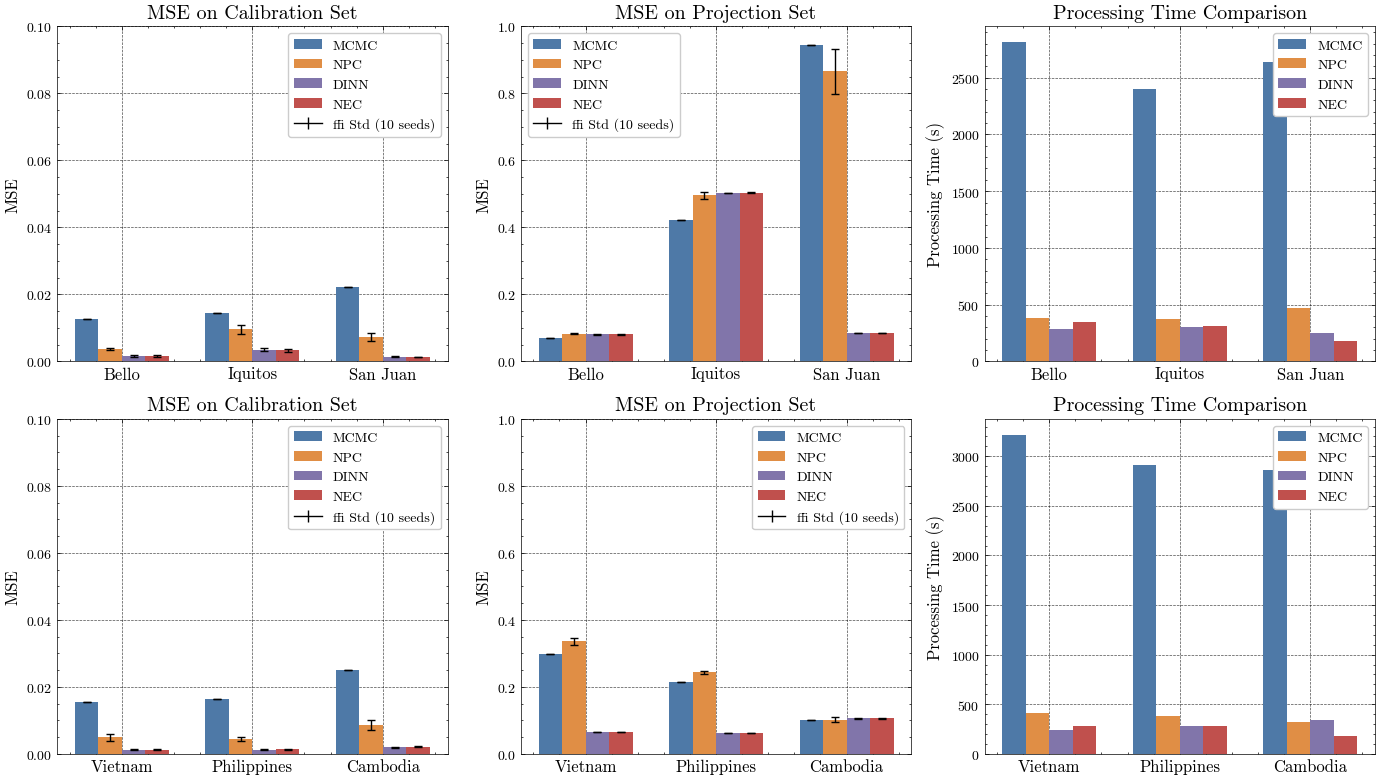

In [46]:
# Visualize the time and error: cities (row 1) and countries (row 2)
from matplotlib.lines import Line2D

labels = ["MCMC", "NPC", "DINN", "NEC"]
colors = ["#4E79A7", "#E08E45", "#8175AA", "#C0504D"]
width = 0.18
offsets = [-1.5 * width, -0.5 * width, 0.5 * width, 1.5 * width]

mse_cali_city = {
    "Bello":    [mse_Hitotal_mcmc_bello_cali, mse_Hitotal_npc_bello_cali,
                 dinns_nec_log1p_mse("bello", "dinn", "calibration"), dinns_nec_log1p_mse("bello", "nec", "calibration")],
    "Iquitos":  [mse_Hitotal_mcmc_iquitos_cali, mse_Hitotal_npc_iquitos_cali,
                 dinns_nec_log1p_mse("iquitos", "dinn", "calibration"), dinns_nec_log1p_mse("iquitos", "nec", "calibration")],
    "San Juan": [mse_Hitotal_mcmc_sanjuan_cali, mse_Hitotal_npc_sanjuan_cali,
                 dinns_nec_log1p_mse("sanjuan", "dinn", "calibration"), dinns_nec_log1p_mse("sanjuan", "nec", "calibration")],
}
mse_cali_city_std = {
    "Bello":    [0.0, mse_Hitotal_npc_bello_cali_std,
                 dinns_nec_log1p_mse_std("bello", "dinn", "calibration"), dinns_nec_log1p_mse_std("bello", "nec", "calibration")],
    "Iquitos":  [0.0, mse_Hitotal_npc_iquitos_cali_std,
                 dinns_nec_log1p_mse_std("iquitos", "dinn", "calibration"), dinns_nec_log1p_mse_std("iquitos", "nec", "calibration")],
    "San Juan": [0.0, mse_Hitotal_npc_sanjuan_cali_std,
                 dinns_nec_log1p_mse_std("sanjuan", "dinn", "calibration"), dinns_nec_log1p_mse_std("sanjuan", "nec", "calibration")],
}
mse_proj_city = {
    "Bello":    [mse_Hitotal_mcmc_bello_proj, mse_Hitotal_npc_bello_proj,
                 dinns_nec_log1p_mse("bello", "dinn", "projection"), dinns_nec_log1p_mse("bello", "nec", "projection")],
    "Iquitos":  [mse_Hitotal_mcmc_iquitos_proj, mse_Hitotal_npc_iquitos_proj,
                 dinns_nec_log1p_mse("iquitos", "dinn", "projection"), dinns_nec_log1p_mse("iquitos", "nec", "projection")],
    "San Juan": [mse_Hitotal_mcmc_sanjuan_proj, mse_Hitotal_npc_sanjuan_proj,
                 dinns_nec_log1p_mse("sanjuan", "dinn", "projection"), dinns_nec_log1p_mse("sanjuan", "nec", "projection")],
}
mse_proj_city_std = {
    "Bello":    [0.0, mse_Hitotal_npc_bello_proj_std,
                 dinns_nec_log1p_mse_std("bello", "dinn", "projection"), dinns_nec_log1p_mse_std("bello", "nec", "projection")],
    "Iquitos":  [0.0, mse_Hitotal_npc_iquitos_proj_std,
                 dinns_nec_log1p_mse_std("iquitos", "dinn", "projection"), dinns_nec_log1p_mse_std("iquitos", "nec", "projection")],
    "San Juan": [0.0, mse_Hitotal_npc_sanjuan_proj_std,
                 dinns_nec_log1p_mse_std("sanjuan", "dinn", "projection"), dinns_nec_log1p_mse_std("sanjuan", "nec", "projection")],
}
process_time_city = {
    "Bello":    [2812.6453, 383, dinns_nec_train_seconds("bello", "dinn"), dinns_nec_train_seconds("bello", "nec")],
    "Iquitos":  [2397.2065, 371, dinns_nec_train_seconds("iquitos", "dinn"), dinns_nec_train_seconds("iquitos", "nec")],
    "San Juan": [2638.1834, 470, dinns_nec_train_seconds("sanjuan", "dinn"), dinns_nec_train_seconds("sanjuan", "nec")],
}

mse_cali_country = {
    "Vietnam":     [mse_Hitotal_mcmc_vietnam_cali, mse_Hitotal_npc_vietnam_cali,
                    dinns_nec_log1p_mse("vietnam", "dinn", "calibration"), dinns_nec_log1p_mse("vietnam", "nec", "calibration")],
    "Philippines": [mse_Hitotal_mcmc_philippines_cali, mse_Hitotal_npc_philippines_cali,
                    dinns_nec_log1p_mse("philippines", "dinn", "calibration"), dinns_nec_log1p_mse("philippines", "nec", "calibration")],
    "Cambodia":    [mse_Hitotal_mcmc_cambodia_cali, mse_Hitotal_npc_cambodia_cali,
                    dinns_nec_log1p_mse("cambodia", "dinn", "calibration"), dinns_nec_log1p_mse("cambodia", "nec", "calibration")],
}
mse_cali_country_std = {
    "Vietnam":     [0.0, mse_Hitotal_npc_vietnam_cali_std,
                    dinns_nec_log1p_mse_std("vietnam", "dinn", "calibration"), dinns_nec_log1p_mse_std("vietnam", "nec", "calibration")],
    "Philippines": [0.0, mse_Hitotal_npc_philippines_cali_std,
                    dinns_nec_log1p_mse_std("philippines", "dinn", "calibration"), dinns_nec_log1p_mse_std("philippines", "nec", "calibration")],
    "Cambodia":    [0.0, mse_Hitotal_npc_cambodia_cali_std,
                    dinns_nec_log1p_mse_std("cambodia", "dinn", "calibration"), dinns_nec_log1p_mse_std("cambodia", "nec", "calibration")],
}
mse_proj_country = {
    "Vietnam":     [mse_Hitotal_mcmc_vietnam_proj, mse_Hitotal_npc_vietnam_proj,
                    dinns_nec_log1p_mse("vietnam", "dinn", "projection"), dinns_nec_log1p_mse("vietnam", "nec", "projection")],
    "Philippines": [mse_Hitotal_mcmc_philippines_proj, mse_Hitotal_npc_philippines_proj,
                    dinns_nec_log1p_mse("philippines", "dinn", "projection"), dinns_nec_log1p_mse("philippines", "nec", "projection")],
    "Cambodia":    [mse_Hitotal_mcmc_cambodia_proj, mse_Hitotal_npc_cambodia_proj,
                    dinns_nec_log1p_mse("cambodia", "dinn", "projection"), dinns_nec_log1p_mse("cambodia", "nec", "projection")],
}
mse_proj_country_std = {
    "Vietnam":     [0.0, mse_Hitotal_npc_vietnam_proj_std,
                    dinns_nec_log1p_mse_std("vietnam", "dinn", "projection"), dinns_nec_log1p_mse_std("vietnam", "nec", "projection")],
    "Philippines": [0.0, mse_Hitotal_npc_philippines_proj_std,
                    dinns_nec_log1p_mse_std("philippines", "dinn", "projection"), dinns_nec_log1p_mse_std("philippines", "nec", "projection")],
    "Cambodia":    [0.0, mse_Hitotal_npc_cambodia_proj_std,
                    dinns_nec_log1p_mse_std("cambodia", "dinn", "projection"), dinns_nec_log1p_mse_std("cambodia", "nec", "projection")],
}
process_time_country = {
    "Vietnam":     [3217.0232, 410, dinns_nec_train_seconds("vietnam", "dinn"), dinns_nec_train_seconds("vietnam", "nec")],
    "Philippines": [2915.1864, 377, dinns_nec_train_seconds("philippines", "dinn"), dinns_nec_train_seconds("philippines", "nec")],
    "Cambodia":    [2864.2839, 317, dinns_nec_train_seconds("cambodia", "dinn"), dinns_nec_train_seconds("cambodia", "nec")],
}

row_data = [
    (list(mse_cali_city.keys()), mse_cali_city, mse_cali_city_std, mse_proj_city, mse_proj_city_std, process_time_city),
    (list(mse_cali_country.keys()), mse_cali_country, mse_cali_country_std, mse_proj_country, mse_proj_country_std, process_time_country),
]

error_kw = {"elinewidth": 1, "capthick": 1}
std_handle = Line2D([0], [0], color="black", lw=1, marker="|", markersize=8, label="\u00b1 Std (10 seeds)")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for row_idx, (regions, mse_cali, mse_cali_std, mse_proj, mse_proj_std, process_time) in enumerate(row_data):
    x = np.arange(len(regions))
    ax_cali, ax_proj, ax_time = axes[row_idx]

    for i, (label, color, offset) in enumerate(zip(labels, colors, offsets)):
        ax_cali.bar(x + offset, [mse_cali[r][i] for r in regions], width,
                     yerr=[mse_cali_std[r][i] for r in regions], capsize=3, error_kw=error_kw,
                     label=label, color=color)
    ax_cali.set_title("MSE on Calibration Set", fontsize="x-large")
    ax_cali.set_ylabel("MSE", fontsize="large")
    ax_cali.set_xticks(x)
    ax_cali.set_xticklabels(regions, fontsize="large")
    cali_handles, cali_labels = ax_cali.get_legend_handles_labels()
    ax_cali.legend(handles=cali_handles + [std_handle], labels=cali_labels + [std_handle.get_label()], fontsize="medium")
    ax_cali.grid(True, linestyle="--", alpha=0.7)
    ax_cali.set_ylim(0, 0.1)

    for i, (label, color, offset) in enumerate(zip(labels, colors, offsets)):
        ax_proj.bar(x + offset, [mse_proj[r][i] for r in regions], width,
                     yerr=[mse_proj_std[r][i] for r in regions], capsize=3, error_kw=error_kw,
                     label=label, color=color)
    ax_proj.set_title("MSE on Projection Set", fontsize="x-large")
    ax_proj.set_ylabel("MSE", fontsize="large")
    ax_proj.set_xticks(x)
    ax_proj.set_xticklabels(regions, fontsize="large")
    proj_handles, proj_labels = ax_proj.get_legend_handles_labels()
    ax_proj.legend(handles=proj_handles + [std_handle], labels=proj_labels + [std_handle.get_label()], fontsize="medium")
    ax_proj.grid(True, linestyle="--", alpha=0.7)
    ax_proj.set_ylim(0, 1)

    for i, (label, color, offset) in enumerate(zip(labels, colors, offsets)):
        ax_time.bar(x + offset, [process_time[r][i] for r in regions], width, label=label, color=color)
    ax_time.set_title("Processing Time Comparison", fontsize="x-large")
    ax_time.set_ylabel("Processing Time (s)", fontsize="large")
    ax_time.set_xticks(x)
    ax_time.set_xticklabels(regions, fontsize="large")
    ax_time.legend(fontsize="medium")
    ax_time.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig("mse_processing_time.png", dpi=700, format='png')
plt.show()

In [56]:
# Print DINN / NEC training time per region (cities + countries), for
# reporting in the paper: total time summed across all seeds, and the
# mean +/- std per seed.
train_time_city_titles = {"bello": "Bello", "iquitos": "Iquitos", "sanjuan": "San Juan"}
train_time_country_titles = {"vietnam": "Vietnam", "philippines": "Philippines", "cambodia": "Cambodia"}

for region_titles in (train_time_city_titles, train_time_country_titles):
    for region, title in region_titles.items():
        for model in ("dinn", "nec"):
            total = dinns_nec_train_seconds(region, model)
            mean = dinns_nec_train_seconds_mean(region, model)
            std = dinns_nec_train_seconds_std(region, model)
            print(
                f"{title} {model.upper()} training time: "
                f"{total:.2f}s total, {mean:.2f} +/- {std:.2f}s per seed"
            )


Bello DINN training time: 288.19s total, 28.82 +/- 10.82s per seed
Bello NEC training time: 345.57s total, 34.56 +/- 14.07s per seed
Iquitos DINN training time: 302.99s total, 30.30 +/- 12.78s per seed
Iquitos NEC training time: 307.95s total, 30.80 +/- 11.47s per seed
San Juan DINN training time: 253.06s total, 25.31 +/- 9.06s per seed
San Juan NEC training time: 180.71s total, 18.07 +/- 3.70s per seed
Vietnam DINN training time: 241.97s total, 24.20 +/- 10.41s per seed
Vietnam NEC training time: 280.09s total, 28.01 +/- 13.18s per seed
Philippines DINN training time: 277.75s total, 27.78 +/- 11.48s per seed
Philippines NEC training time: 281.98s total, 28.20 +/- 7.55s per seed
Cambodia DINN training time: 344.12s total, 34.41 +/- 11.73s per seed
Cambodia NEC training time: 180.15s total, 18.01 +/- 3.85s per seed


# Marginal Posterior

In [47]:
import h5py
import scipy
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

def plot_density(ax, series, param, min_scale, max_scale, quantile_threshold=0.99):
    """Overlay KDE density curves (+ mean/mode markers), each normalized to peak=1.

    Normalizing avoids one tightly-clustered method (e.g. DINN, whose seeds
    converge to near-identical values) producing a KDE spike that dwarfs
    methods with more spread on the shared y-axis.
    """
    x_range = np.linspace(min_scale, max_scale, 200)
    for data, label, color in series:
        try:
            kde = gaussian_kde(data, bw_method=1)
            y = kde(x_range)
        except np.linalg.LinAlgError:
            # Fallback to histogram-based density estimation
            y, bin_edges = np.histogram(data, bins=50, density=True)
            x_range = (bin_edges[:-1] + bin_edges[1:]) / 2

        y = y / y.max()

        ax.plot(x_range, y, color=color, lw=2, label=label)
        ax.fill_between(x_range, y, alpha=0.3, color=color)

        mean_val = np.mean(data)
        mean_y = np.interp(mean_val, x_range, y)
        ax.scatter(mean_val, mean_y, color='black', s=30, marker='o', zorder=5)

        mode_idx = np.argmax(y)
        ax.scatter(x_range[mode_idx], y[mode_idx], color='grey', s=30, marker='D', zorder=5)

    ax.set_ylim(0, 1.15)


### Bello, Iquitos and San Juan cities

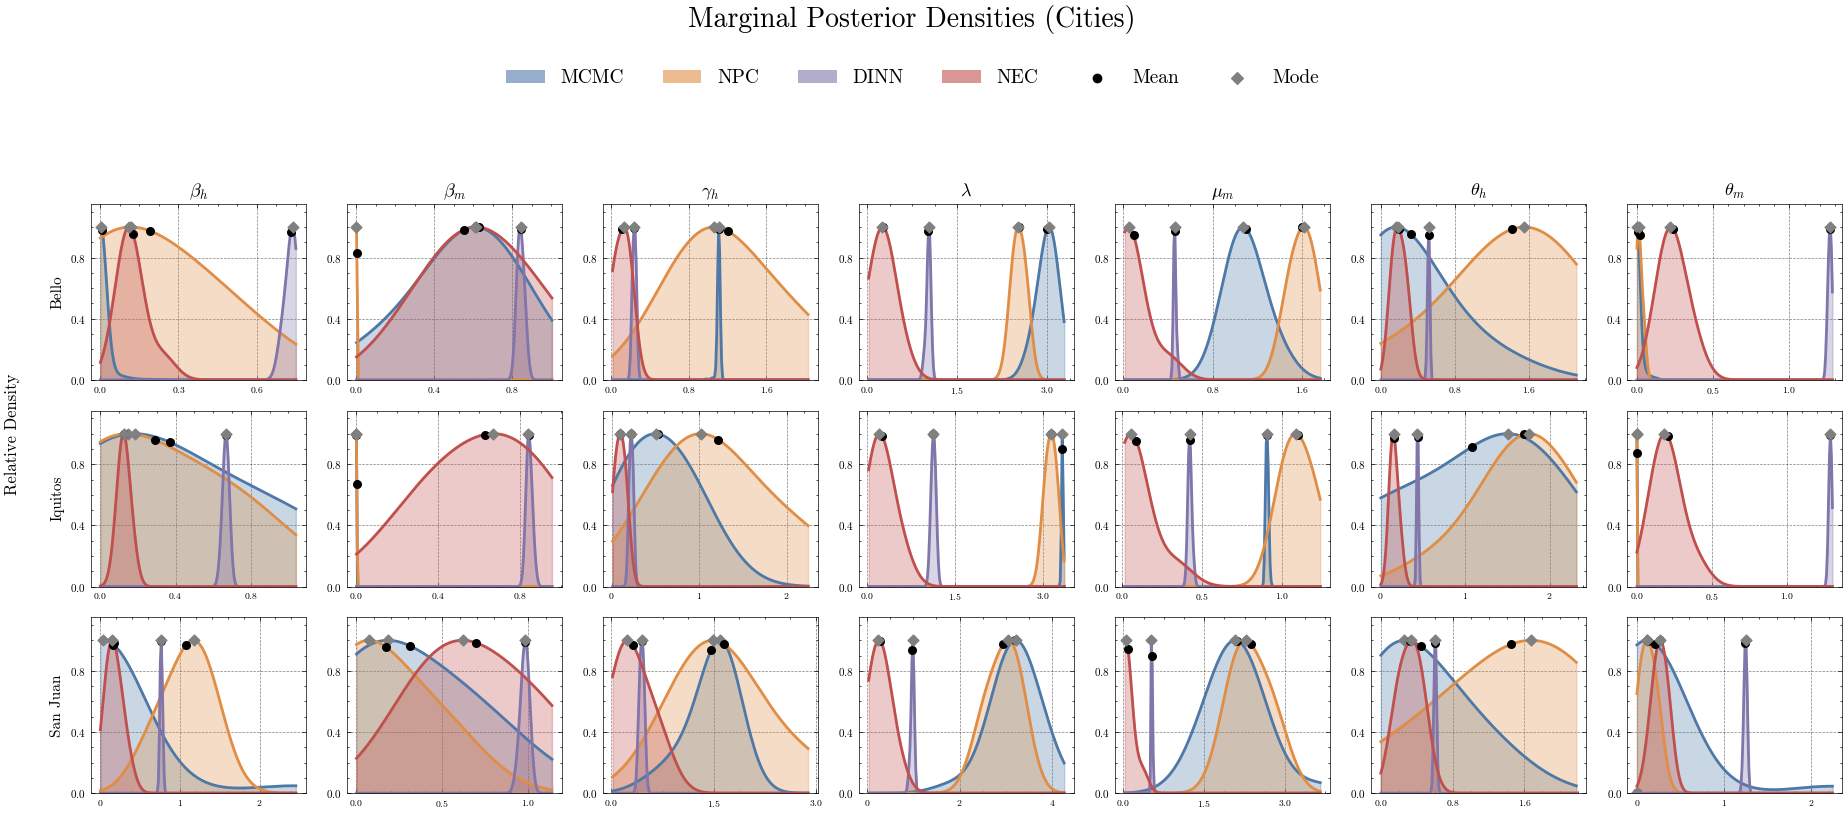

In [57]:
import glob
import pandas as pd

param_names = ['beta_h', 'beta_m', 'gamma_h', 'lambda',
               'mu_m', 'theta_h', 'theta_m']
population = 544549

# Define citys to plot
cities = ['bello', 'iquitos', 'sanjuan']
city_titles = ['Bello', 'Iquitos', 'San Juan']

DINNS_NEC_PARAMS_DIR = "../outputs/dinns_nec_params"
REGION_KEY = {
    'bello': 'bello', 'iquitos': 'iquitos', 'sanjuan': 'sanjuan',
    'vietnam': 'vn', 'philippines': 'phi', 'cambodia': 'cam',
}


def load_dinns_nec_final_params(region, model):
    """Final-epoch parameter vector per seed: (n_seeds, len(param_names)), in `param_names` order."""
    region_key = REGION_KEY[region]
    seed_files = sorted(glob.glob(f"{DINNS_NEC_PARAMS_DIR}/{region_key}/seed*/{model}.csv"))
    if not seed_files:
        raise FileNotFoundError(
            f"No {model} parameter CSVs found under "
            f"{DINNS_NEC_PARAMS_DIR}/{region_key}/seed*/{model}.csv -- "
            "run the full DINN/NEC sweep first (see baseline_all_results.ipynb)."
        )
    rows = []
    for path in seed_files:
        df = pd.read_csv(path).sort_values("epoch")
        final = df.iloc[-1]
        rows.append([final[p] for p in param_names])
    return np.array(rows)


METHOD_COLORS = {"MCMC": "#4E79A7", "NPC": "#E08E45", "DINN": "#8175AA", "NEC": "#C0504D"}

# Load data for all citys
all_params_mcmc = []
all_params_npc = []
all_params_dinn = []
all_params_nec = []

for city in cities:
    # Load MCMC parameters
    mat = scipy.io.loadmat(f"{city}/{city}_MCMC_all_params.mat")
    params_mcmc = mat[f'{city}_mcmc']
    all_params_mcmc.append(params_mcmc)

    # Load NPC parameters
    param_list = []
    folders = sorted([f for f in os.listdir(f"{city}/data") if f.startswith("uni")])
    for folder in folders:
        h5_path = os.path.join(f"{city}/data", folder, "data.h5")
        if not os.path.exists(h5_path):
            print(f"File not found: {h5_path}")
            continue
        with h5py.File(h5_path, "r") as hf:
            params = hf["Dengue"]["parameters"][-1, :]
            param_list.append(params)
    params_npc = np.vstack(param_list)
    all_params_npc.append(params_npc)

    # Load DINN / NEC parameters (final epoch per seed)
    all_params_dinn.append(load_dinns_nec_final_params(city, "dinn"))
    all_params_nec.append(load_dinns_nec_final_params(city, "nec"))

# Define parameter names for axis titles
math_param_names = {
    "beta_h": r"$\beta_{h}$", "beta_m": r"$\beta_{m}$",
    "gamma_h": r"$\gamma_{h}$", "lambda": r"$\lambda$", "mu_m": r"$\mu_{m}$",
    "theta_h": r"$\theta_{h}$", "theta_m": r"$\theta_{m}$"
}

# Clean grid: one column per parameter, no dedicated legend column -- the
# legend lives in a single horizontal strip above the grid instead.
nrows, ncols = len(cities), len(param_names)
fig, axs = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.6 * nrows))

for city_idx, (city, city_title) in enumerate(zip(cities, city_titles)):
    params_mcmc = all_params_mcmc[city_idx]
    params_npc = all_params_npc[city_idx]
    params_dinn = all_params_dinn[city_idx]
    params_nec = all_params_nec[city_idx]

    for param_idx, param in enumerate(param_names):
        ax = axs[city_idx, param_idx]
        all_data = {
            "MCMC": params_mcmc[param_idx, :],
            "NPC": params_npc[:, param_idx],
            "DINN": params_dinn[:, param_idx],
            "NEC": params_nec[:, param_idx],
        }

        # Trim each method's own samples to its central 99% interval. With very
        # few samples (e.g. a smoke test with 1-2 seeds), the 1%/99% quantile
        # trim can mathematically exclude every point -- fall back to the
        # untrimmed data rather than produce an empty array.
        trimmed = {}
        for label, data in all_data.items():
            q_low, q_high = np.quantile(data.ravel(), [0.01, 0.99])
            mask = (data >= q_low) & (data <= q_high)
            trimmed[label] = data[mask] if mask.any() else data

        min_scale = min(d.min() for d in trimmed.values())
        max_scale = max(d.max() for d in trimmed.values())
        series = [(trimmed[label], label, METHOD_COLORS[label]) for label in ["MCMC", "NPC", "DINN", "NEC"]]
        plot_density(ax, series, param, min_scale, max_scale)

        # Set titles only for top row
        if city_idx == 0:
            ax.set_title(math_param_names[param], fontsize=13)

        # Set row label only for first column
        if param_idx == 0:
            ax.set_ylabel(city_title, fontsize=11)

        # Compact, readable ticks instead of hiding the axes entirely
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelsize=7)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(3))

fig.supylabel("Relative Density", fontsize=12)

# Single shared legend in a horizontal strip above the grid (no blank
# "legend column" eating space from the data columns).
handles = [plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["MCMC"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["NPC"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["DINN"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["NEC"], alpha=0.6),
           plt.scatter([0], [0], color='black', marker='o'),
           plt.scatter([0], [0], color='grey', marker='D')]
labels = ['MCMC', 'NPC', 'DINN', 'NEC', 'Mean', 'Mode']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=len(labels), frameon=False, fontsize=14)

fig.suptitle("Marginal Posterior Densities (Cities)", fontsize=20, y=1.05)
fig.tight_layout(rect=(0.02, 0, 1, 0.90))
plt.savefig('marginal_posterior_city.png', dpi=200, format='png')
plt.show()

### Vietnam, Cambodia and the Philippines

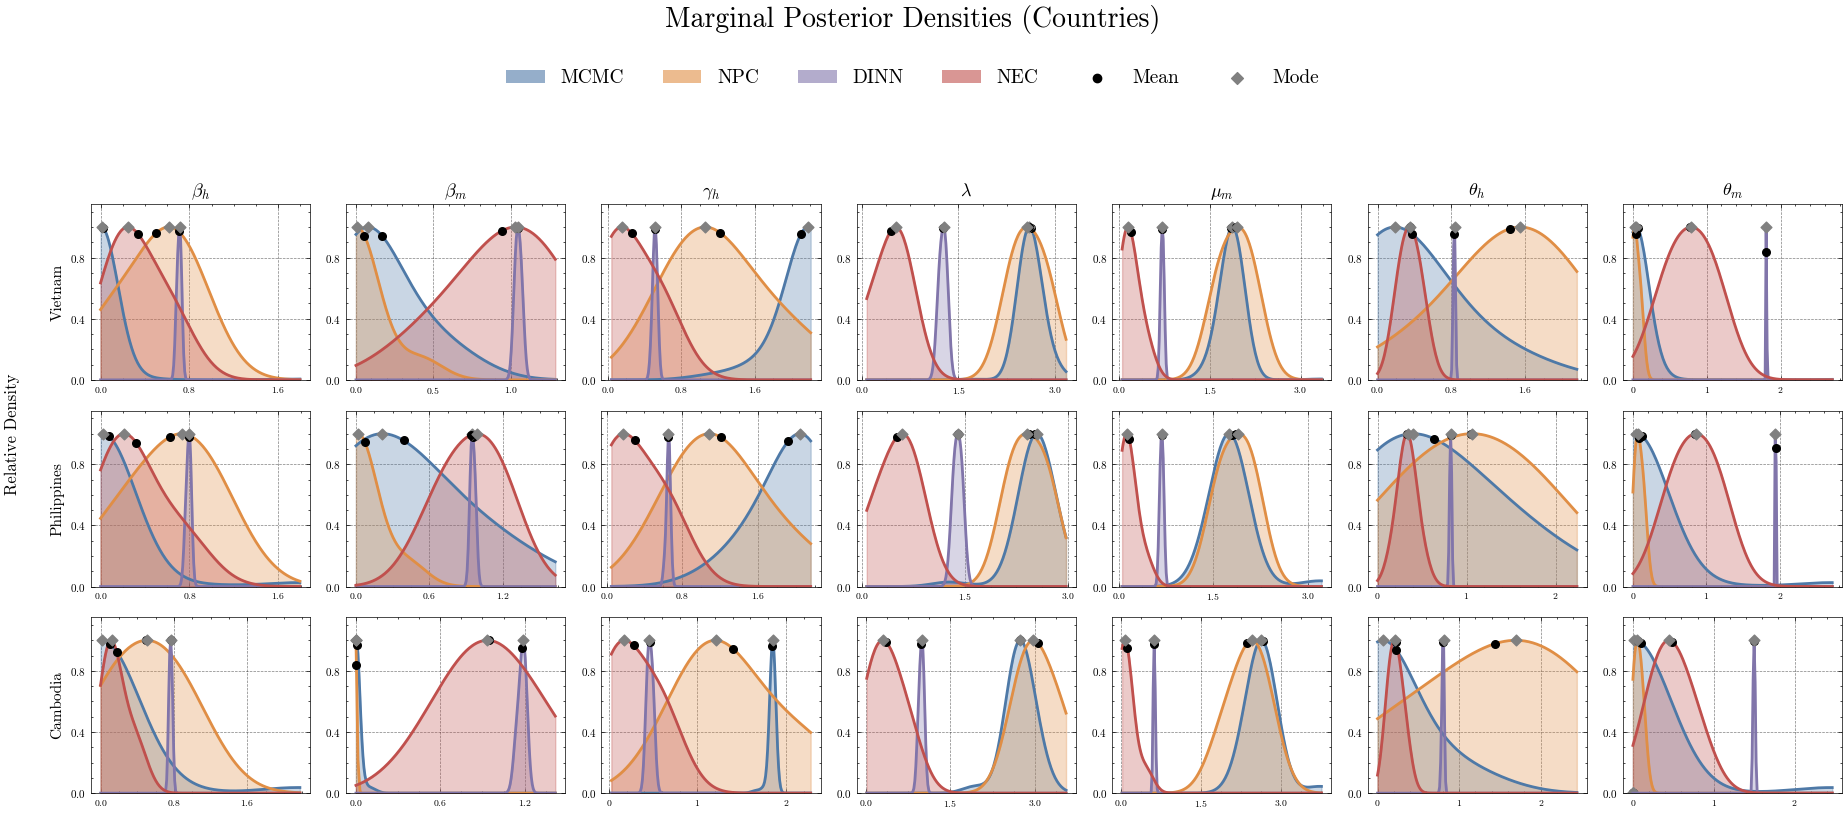

In [58]:
import glob
import pandas as pd

param_names = ['beta_h', 'beta_m', 'gamma_h', 'lambda',
               'mu_m', 'theta_h', 'theta_m']
population = 544549

# Define countrys to plot
countries = ['vietnam', 'philippines', 'cambodia']
country_titles = ['Vietnam', 'Philippines', 'Cambodia']

DINNS_NEC_PARAMS_DIR = "../outputs/dinns_nec_params"
REGION_KEY = {
    'bello': 'bello', 'iquitos': 'iquitos', 'sanjuan': 'sanjuan',
    'vietnam': 'vn', 'philippines': 'phi', 'cambodia': 'cam',
}


def load_dinns_nec_final_params(region, model):
    """Final-epoch parameter vector per seed: (n_seeds, len(param_names)), in `param_names` order."""
    region_key = REGION_KEY[region]
    seed_files = sorted(glob.glob(f"{DINNS_NEC_PARAMS_DIR}/{region_key}/seed*/{model}.csv"))
    if not seed_files:
        raise FileNotFoundError(
            f"No {model} parameter CSVs found under "
            f"{DINNS_NEC_PARAMS_DIR}/{region_key}/seed*/{model}.csv -- "
            "run the full DINN/NEC sweep first (see baseline_all_results.ipynb)."
        )
    rows = []
    for path in seed_files:
        df = pd.read_csv(path).sort_values("epoch")
        final = df.iloc[-1]
        rows.append([final[p] for p in param_names])
    return np.array(rows)


METHOD_COLORS = {"MCMC": "#4E79A7", "NPC": "#E08E45", "DINN": "#8175AA", "NEC": "#C0504D"}

# Load data for all countrys
all_params_mcmc = []
all_params_npc = []
all_params_dinn = []
all_params_nec = []

for country in countries:
    # Load MCMC parameters
    mat = scipy.io.loadmat(f"{country}/{country}_MCMC_all_params.mat")
    params_mcmc = mat[f'{country}_mcmc']
    all_params_mcmc.append(params_mcmc)

    # Load NPC parameters
    param_list = []
    folders = sorted([f for f in os.listdir(f"{country}/data") if f.startswith("uni")])
    for folder in folders:
        h5_path = os.path.join(f"{country}/data", folder, "data.h5")
        if not os.path.exists(h5_path):
            print(f"File not found: {h5_path}")
            continue
        with h5py.File(h5_path, "r") as hf:
            params = hf["Dengue"]["parameters"][-1, :]
            param_list.append(params)
    params_npc = np.vstack(param_list)
    all_params_npc.append(params_npc)

    # Load DINN / NEC parameters (final epoch per seed)
    all_params_dinn.append(load_dinns_nec_final_params(country, "dinn"))
    all_params_nec.append(load_dinns_nec_final_params(country, "nec"))

# Define parameter names for axis titles
math_param_names = {
    "beta_h": r"$\beta_{h}$", "beta_m": r"$\beta_{m}$",
    "gamma_h": r"$\gamma_{h}$", "lambda": r"$\lambda$", "mu_m": r"$\mu_{m}$",
    "theta_h": r"$\theta_{h}$", "theta_m": r"$\theta_{m}$"
}

# Clean grid: one column per parameter, no dedicated legend column -- the
# legend lives in a single horizontal strip above the grid instead.
nrows, ncols = len(countries), len(param_names)
fig, axs = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 2.6 * nrows))

for country_idx, (country, country_title) in enumerate(zip(countries, country_titles)):
    params_mcmc = all_params_mcmc[country_idx]
    params_npc = all_params_npc[country_idx]
    params_dinn = all_params_dinn[country_idx]
    params_nec = all_params_nec[country_idx]

    for param_idx, param in enumerate(param_names):
        ax = axs[country_idx, param_idx]
        all_data = {
            "MCMC": params_mcmc[param_idx, :],
            "NPC": params_npc[:, param_idx],
            "DINN": params_dinn[:, param_idx],
            "NEC": params_nec[:, param_idx],
        }

        # Trim each method's own samples to its central 99% interval. With very
        # few samples (e.g. a smoke test with 1-2 seeds), the 1%/99% quantile
        # trim can mathematically exclude every point -- fall back to the
        # untrimmed data rather than produce an empty array.
        trimmed = {}
        for label, data in all_data.items():
            q_low, q_high = np.quantile(data.ravel(), [0.01, 0.99])
            mask = (data >= q_low) & (data <= q_high)
            trimmed[label] = data[mask] if mask.any() else data

        min_scale = min(d.min() for d in trimmed.values())
        max_scale = max(d.max() for d in trimmed.values())
        series = [(trimmed[label], label, METHOD_COLORS[label]) for label in ["MCMC", "NPC", "DINN", "NEC"]]
        plot_density(ax, series, param, min_scale, max_scale)

        # Set titles only for top row
        if country_idx == 0:
            ax.set_title(math_param_names[param], fontsize=13)

        # Set row label only for first column
        if param_idx == 0:
            ax.set_ylabel(country_title, fontsize=11)

        # Compact, readable ticks instead of hiding the axes entirely
        ax.tick_params(axis='y', labelsize=8)
        ax.tick_params(axis='x', labelsize=7)
        ax.xaxis.set_major_locator(plt.MaxNLocator(3))
        ax.yaxis.set_major_locator(plt.MaxNLocator(3))

fig.supylabel("Relative Density", fontsize=12)

# Single shared legend in a horizontal strip above the grid (no blank
# "legend column" eating space from the data columns).
handles = [plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["MCMC"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["NPC"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["DINN"], alpha=0.6),
           plt.Rectangle((0, 0), 1, 1, fc=METHOD_COLORS["NEC"], alpha=0.6),
           plt.scatter([0], [0], color='black', marker='o'),
           plt.scatter([0], [0], color='grey', marker='D')]
labels = ['MCMC', 'NPC', 'DINN', 'NEC', 'Mean', 'Mode']
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=len(labels), frameon=False, fontsize=14)

fig.suptitle("Marginal Posterior Densities (Countries)", fontsize=20, y=1.05)
fig.tight_layout(rect=(0.02, 0, 1, 0.90))
plt.savefig('marginal_posterior_country.png', dpi=200, format='png')
plt.show()